# 认识 Jupyter Notebook

把python程序放在 Notebook 中分段运行。它像一本可以执行代码的实验记录本：说明、公式、代码和结果可以放在一起。

| 普通脚本 `.py` | Notebook `.ipynb` |
| --- | --- |
| 通常用 `python 文件名.py` 启动，按程序流程执行 | 可以逐个执行单元格，也可以全部运行 |
| 每次用上述命令启动，通常是一个新进程 | 同一个内核会保留之前创建的变量 |
| 主要保存代码和注释 | 可以一起保存代码、说明、公式和输出 |

### 公式也可以放进 Notebook

**Markdown 单元格**具有接近latex的公式表达能力，你可以在这里编辑大多数的latex公式

$$
y=f(x) \cdot \frac{x^2}{5}.
$$

**先选对内核。** 内核（Kernel）是实际执行代码的程序。今天做神经网络演示时，选择装有 PyTorch 的 `pubpy` 环境。点击单元格旁的运行按钮，或按 `Shift+Enter`，即可执行代码。

下面先看：当前究竟是哪一个 Python 在运行？


In [542]:
import sys
print("当前运行代码的 Python：")
print(sys.executable)

当前运行代码的 Python：
/opt/miniconda/envs/pubpy/bin/python


In [543]:
x = 1
print("设置 x =", x)


设置 x = 1


In [544]:
x = x + 1
print(" x =", x)


 x = 2


### 其他运行注意事项

- **中断运行**：停止当前计算，通常保留已经创建的变量；不会撤销之前的操作。
- **重启内核**：清空内存中的变量，需要重新运行代码。调试结束后，试一次“重启内核并运行全部”，检查程序是否能按顺序运行。
- **关闭内核**：结束后台运行。在vscode中关闭标签页就会关闭内核。
- **保存文件**：Notebook 可以保存代码和输出，但不会保存内存中所有变量。训练好的模型参数仍需单独保存。

参考：[Jupyter 官方说明](https://jupyter-notebook.readthedocs.io/en/stable/notebook.html)。

### 神经网络部分

In [545]:
import numpy as np
import torch
import torch.nn as nn
import os
import time

# torch.manual_seed(seed=42) 
# 如果想要能够复现完全一样的训练结果的话，可以用这个命令固定每一次的torch包的随机种子，不过仅仅是固定torch包的随机种子，其他包的随机种子还是不固定的
# 但设备、版本和部分运算仍可能影响结果


In [546]:
class Mynetwork(nn.Module):                                        # class 定义一个神经网络类，继承自nn.Module的基础模板，可以使用nn.Module的各种方法和属性
    def __init__(self,input_num=1 , out_num=1,hidden_num=32):      # 创建网络时进行的初始化操作，input_num是输入层的默认神经元数量，hidden_num是隐藏层的默认神经元数量
        super().__init__()                                         # 这个是固定写法，表示调用父类的初始化方法，确保父类的初始化逻辑被执行，对于我们来说，记住这个必写就可以了。
        self.MLP=nn.Sequential(                                    # 这里定义了一个我们自定义的属性“MLP”，使用nn.Sequential将多个层按顺序组合起来
            nn.Linear(input_num, hidden_num),                      # nn.Sequential是一个容器，可以将多个层组合成一个整体，按顺序执行
            nn.ELU(),                                              # 这种写法相比于我们第三次作业中的网络分层定义，更加简洁，避免了去定义每一层的变量名，不过灵活性会稍微差一些
            nn.Linear(hidden_num,hidden_num),                      # nn.Linear是一个全连接层，nn.ELU()是一个激活函数层，ELU是指数线性单元（Exponential Linear Unit）
            nn.ELU(),
            nn.Linear(hidden_num,hidden_num),                      # 关于网络参数的选择，目前这样的一个网络算是一种较小的test型网络。
            nn.ELU(),                                              # 在实际应用中，选择网络参数需要根据具体问题进行调试和优化，可能需要尝试不同的网络结构、层数、神经元数量等，以找到最适合的配置。
            nn.Linear(hidden_num,out_num),                         # 在探索参数选择的过程中，首先最重要的是要先通过小步扩展来判断自己的问题中，网络规模扩张（深、宽、数据类型）带来的计算内存开销、时间消耗的增长。                                                           
        )                                                          # 由此来先确定自己的计算资源和时间所能承受的范围，然后再在这个范围内去按计划尝试不同的网络参数选择，最终找到一个最优的网络结构。
    def forward(self,x):
        return self.MLP(x)                                         # 由于我们用nn.Sequential定义了一个整体的网络，所以在前向传播时，直接调用self.MLP(x)就可以了
    

In [547]:
'''
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2*N*10, layer_num)
        self.fc2 = nn.Linear(layer_num, layer_num)
        self.fc3 = nn.Linear(layer_num, (N+1) * 10)  # 输出 N+1 个位置，每个位置 10 个类别

    def forward(self, x: torch.Tensor):
        x = x.view(-1, 2*N*10)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        x = x.view(-1,( N+1)* 10)
        x = torch.log_softmax(x, dim=1)  # 输出概率分布的对数值。用 log_softmax 代替 softmax，以防止数值不稳定
        return x
'''

'\n    def __init__(self):\n        super().__init__()\n        self.fc1 = nn.Linear(2*N*10, layer_num)\n        self.fc2 = nn.Linear(layer_num, layer_num)\n        self.fc3 = nn.Linear(layer_num, (N+1) * 10)  # 输出 N+1 个位置，每个位置 10 个类别\n\n    def forward(self, x: torch.Tensor):\n        x = x.view(-1, 2*N*10)\n        x = torch.relu(self.fc1(x))\n        x = torch.relu(self.fc2(x))\n        x = self.fc3(x)\n        x = x.view(-1,( N+1)* 10)\n        x = torch.log_softmax(x, dim=1)  # 输出概率分布的对数值。用 log_softmax 代替 softmax，以防止数值不稳定\n        return x\n'

In [548]:
def potential(x):                                  # 这个是我们要拟合的目标函数
    y=x*torch.sin(torch.pi*x*2/3)+x**2*2+10
    return y

# 因为这里我们的目标函数已经清晰，如何生成训练数据非常容易，所以我们不需要使用例如DataLoader这样的工具来管理、操作。不过这个工具的使用也不难，大家可以自行参考相关文档

In [549]:
dtype=torch.float32                    # 数据类型，datatype，请根据具体情况选择所需的数据精度，足够表示，不影响训练就可以了
device=torch.device("cuda:0" if torch.cuda.is_available() else "cpu") 
# 计算设备选择，cuda就是用显卡设备来训练，cuda:0就是指定第一块显卡，cpu就是用电脑的CPU来训练。如果不写device去指定，那么会默认直接用CPU。
# 如果你训练的时候，发现第一块显卡被其他同学占用了，你可以自己指定换成cuda:1,就是第二块显卡，cuda:2就是第三块显卡，依次类推
# 判断显卡是否繁忙主要看 Memory-Usage 和 GPU-Util，前者是显存占用率，后者是计算占用率
# 可以用watch -n 1 nvidia-smi命令来实时查看GPU的使用情况（-n 1表示每1秒更新一次），或者使用nvitop指令，界面更清楚
# 而通常查看CPU的使用情况可以用htop指令，或者top，前者界面更清楚，后者是最基本的指令。

La=-12    # 左边界a
Lb =12    # 右边界b
N = 800   # 格点数量,这里的格点数量，就类似于我们通常情况下的“batch size”了，也就是一次梯度下降时使用的累计样本数量

grid=torch.linspace(La,Lb,N,dtype=dtype,device=device,requires_grad=False) # 用torch定义的格点，指定了数据类型和设备，并且指定该类数据不需要计算梯度。这里我们做演示，就采用固定格点来训练，训练会方便一些，更快。
grid=grid.unsqueeze(-1)                                                    # 这里我们用unsqueeze把grid的形状从(N,)变成了(N,1)，因为我们定义的网络输入层是1个，所以这里需要把grid变成(N,1)的形状。

# 你可以尝试注释掉unsqueeze这一行，看看会有什么报错

epoch=12000  # 训练轮数
lr=0.01      # 起始学习率


In [550]:
model=Mynetwork(hidden_num=64).to(device=device,dtype=dtype) # 这里我们主动指定了参数hidden_num=64
optimizer=torch.optim.Adam(model.parameters(),lr=lr)         # model.parameters()是获取模型的所有参数，注意到这个参数我们并没有主动定义，实际上就是继承自nn.Module，返回的是一个迭代器，里面包含了所有模型参数
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,patience=30,threshold=1e-4) 
# Plateau 是“高原；稳定期”的意思，threshold是阈值，patience是耐心值，意思是如果连续30次训练loss没有下降超过1e-4，那么就降低学习率
loss_fn=nn.MSELoss()  # 损失函数，MSELoss是均方误差损失函数，常用于回归问题，也可以尝试其他各种各样的损失函数

loss_list=[]          # 列表用于记录训练过程中的loss变化情况
init_time=time.time() # 标记训练开始时间

for i in range(epoch):
    optimizer.zero_grad()        # 清零梯度，避免梯度累加
    
    # grid = La + (Lb - La) * torch.rand(N, 1, dtype=dtype, device=device) # 可以去掉注释，尝试用随机点试试看训练效果如何
    f_Value=model(grid)
    f_Value_real=potential(grid)
    
    
    train_loss=loss_fn(f_Value,f_Value_real)   # 用前面定义的损失函数来计算当次训练的loss
    train_loss.backward()                      # 反向传播，计算梯度
    optimizer.step()                           # 按优化器方案更新参数
    
    loss_list.append(train_loss.item())        # 记录训练过程中的loss变化情况，train_loss.item()是把tensor类型的loss转换成python的float类型，方便可视化   
    
    if i%100==0:
        print(f'epoch:{i},train_loss:{train_loss},time:{time.time()-init_time},lr:{optimizer.param_groups[0]["lr"]}')  # 定时反馈训练情况
    
    scheduler.step(train_loss)
    if optimizer.param_groups[0]["lr"] <= 1.1e-7:
        print(f'epoch:{i},train_loss:{train_loss},time:{time.time()-init_time},lr:{optimizer.param_groups[0]["lr"]}')  # 如果学习率已经小于1.1e-7了，就及时阻断，因为后续的训练收效甚微，浪费时间
        break
print('terminal epoch: ',i+1)


epoch:0,train_loss:18411.001953125,time:0.004842519760131836,lr:0.01
epoch:100,train_loss:110.85800170898438,time:0.23454523086547852,lr:0.01
epoch:200,train_loss:17.58053207397461,time:0.4712390899658203,lr:0.01
epoch:300,train_loss:15.190961837768555,time:0.7012531757354736,lr:0.01
epoch:400,train_loss:14.829568862915039,time:0.9337944984436035,lr:0.01
epoch:500,train_loss:14.628449440002441,time:1.165781021118164,lr:0.01
epoch:600,train_loss:14.47785758972168,time:1.3979310989379883,lr:0.01
epoch:700,train_loss:14.348600387573242,time:1.6317288875579834,lr:0.01
epoch:800,train_loss:15.208807945251465,time:1.8647007942199707,lr:0.01
epoch:900,train_loss:14.202492713928223,time:2.090874671936035,lr:0.001
epoch:1000,train_loss:14.187517166137695,time:2.3278872966766357,lr:0.001
epoch:1100,train_loss:14.172142028808594,time:2.555849313735962,lr:0.001
epoch:1200,train_loss:14.156261444091797,time:2.7881226539611816,lr:0.001
epoch:1300,train_loss:14.139301300048828,time:3.0212368965148926

## PyTorch 的张量与自动求导

PyTorch 用 `Tensor`（张量）保存数据。除了保存数值，它还可以记录数据经过了哪些计算，并据此自动计算导数。这些运算之间的联系称为**计算图**。

`requires_grad` 表示是否需要跟踪求导。它为 `True`，并不意味着梯度已经算出来了。

### 对照上面的训练程序

| 对象 | 是否需要梯度 | 作用 |
| --- | --- | --- |
| `grid` | 否 | 输入坐标，是已知数据 |
| `f_Value_real` | 否 | 由目标函数计算的正确答案 |
| 网络的权重和偏置 | 是，默认开启 | 训练中需要调整的参数 |
| `f_Value` | 是 | 预测依赖网络参数，因此会记录计算过程 |
| `train_loss` | 是 | 损失依赖预测，可以沿计算图求导 |

**输入不需要梯度，也不妨碍训练网络。** 本例要计算的是“损失对网络参数的导数”，用来判断参数应该怎样调整。

### 一次训练更新做了什么？

1. `optimizer.zero_grad()`：清除上一次留下的参数梯度。
2. `f_Value = model(grid)`：计算预测，并记录计算过程。
3. `train_loss = loss_fn(f_Value, f_Value_real)`：计算预测与答案的差距。
4. `train_loss.backward()`：沿计算图反向求导，将梯度累积到网络参数的 `.grad` 中。
5. `optimizer.step()`：利用这些梯度更新参数。

注意：**`backward()` 计算梯度，`step()` 才更新参数。** PyTorch 默认会累积梯度，所以普通训练通常每次更新前都要清除旧梯度。

### 为什么记录损失时使用 `.item()`？

`train_loss` 是一个参与自动求导的标量张量；`train_loss.item()` 则取出它的数值，变成普通 Python 数字，方便打印和保存。

因此，记录损失可以写：

`loss_list.append(train_loss.item())`

但计算用于训练的损失时，不能提前用 `.item()` 把预测转成普通数字，否则会断开求导链路。

类似地，`detach()` 会得到脱离当前计算图的张量；`torch.no_grad()` 可以临时停止记录计算图。它们适合绘图和预测检查，不应包住需要反向传播的训练计算。

In [557]:
# 一个带梯度的数据，其梯度是可以查看的
a=torch.linspace(-10,10,5,dtype=dtype,device=device,requires_grad=True) 
b=a**2+3*a+5
c=b.sum()
c.backward()
print(a.grad)
print(b.grad)  

# 可以看看b的梯度，应该是None，因为b不是叶子节点，叶子节点才会有梯度，b是由a计算出来的，所以b的梯度不会被保留，除非我们在定义b的时候加上retain_grad()，例如b.retain_grad()，这样就可以保留b的梯度了

tensor([-17.,  -7.,   3.,  13.,  23.], device='cuda:0')
None


/tmp/ipykernel_1992701/1633435708.py:7: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at /pytorch/build/aten/src/ATen/core/TensorBody.h:489.)
  print(b.grad)


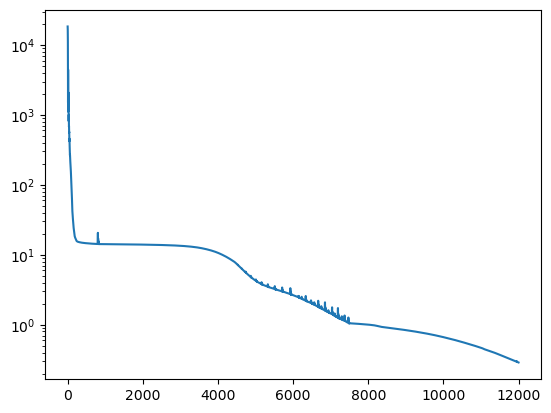

In [558]:
import matplotlib.pyplot as plt   # 导入matplotlib.pyplot模块，用于绘制图形，这个不详细介绍了，大家可以自己参考pyplot的官方文档

plt.plot(loss_list)
plt.yscale('log')
plt.show()

In [559]:
#保存模型参数
os.makedirs(f'./model_para', exist_ok=True)  # 前面加f是可以让后面路径中，{}里面的变量被识别，例如可以加上你的时间戳
model_path=f'./model_para/model_class.pth'
torch.save(model.state_dict(), model_path)   # model.state_dict()是获取模型的所有参数，保存为一个字典，torch.save()是保存这个字典到指定路径


In [560]:
# 读取模型参数
model_path=f'./model_para/model_class.pth'
model = Mynetwork(hidden_num=64).to(device=device,dtype=dtype)  # 读取模型参数时，需要重新创建一个模型实例，并且要确保模型的结构和参数数量与保存时一致，否则会报错
model.load_state_dict(torch.load(model_path))                   # 导入模型参数
model.eval()                                                    # 这个是把模型设置为评估模式，主要是为了关闭dropout和batch normalization等训练时特有的操作

Mynetwork(
  (MLP): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ELU(alpha=1.0)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

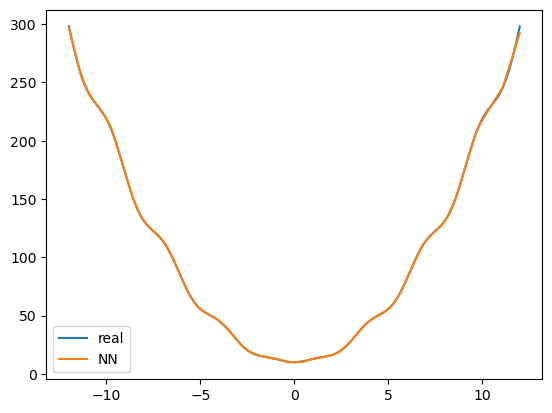

In [561]:
grid=torch.linspace(La,Lb,N,dtype=dtype,device=device)
grid=grid.unsqueeze(-1)

f_network=model(grid)
f_network=f_network.cpu().detach().numpy()  # 这里的.cpu()是把数据从GPU上转移到CPU上，detach()是得到脱离当前计算图的张量，numpy()是把tensor类型的数据转换成numpy数组类型，这样就可以用matplotlib来绘图了

f_real=potential(grid)
f_real=f_real.cpu().detach().numpy()

plt.plot(grid.cpu().detach().numpy(),f_real,label='real')
plt.plot(grid.cpu().detach().numpy(),f_network,label='NN')
plt.legend()
plt.show()

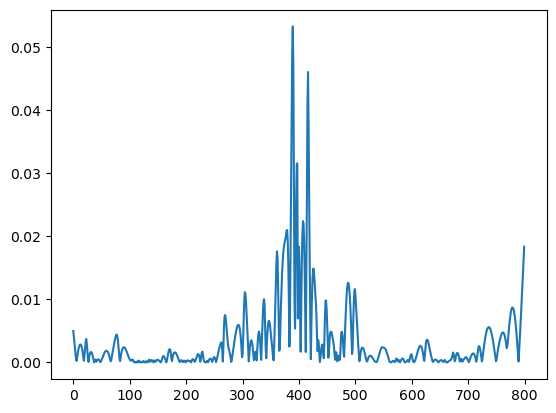

In [562]:
f_network=model(grid)
V_model=f_network.flatten().detach().cpu().numpy()

f_real=potential(grid)
V_real=f_real.flatten().detach().cpu().numpy()

plt.plot(np.abs((V_real-V_model)/V_real))
# plt.yscale('log')
plt.show()